### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)
    os.makedirs(os.path.join(tmpdir, "chirp"))

/flash/ReiterU/tmp/tomo_ZNSWDEBKEOLC


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig
from scipy.stats import pearsonr

In [4]:
import sys
sys.path.append("./")
from monitor_flip_functions import plot_cluster_average, plot_clustering2

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [6]:
database = [
    {
        "name": "1",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250121_rec8-rec9/response_table_combined.hdf5",
    },
    {
        "name": "2",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250212_rec4-rec5/response_table_combined.hdf5",
    },
    {
        "name": "3",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250318_rec9-rec10/response_table_combined.hdf5",
    },
    {
        "name": "4",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250502_OGL_monitor_flip_analysis/20250521_rec7-rec9/response_table_combined.hdf5",
    },
    {
        "name": "5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250212_rec2-rec3/response_table_combined.hdf5",
    },
    {
        "name": "6",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec5-rec7/response_table_combined.hdf5",
    },
    {
        "name": "7",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250520_rec8-rec9/response_table_combined.hdf5",
    },
    {
        "name": "8",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250522_rec3-rec4/response_table_combined.hdf5",
    },
     {
        "name": "9",
         "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250528_IGL_monitor_flip_analysis/20250522_rec5-rec6/response_table_combined.hdf5",
    },
]


### load data

In [7]:
with pd.HDFStore("/bucket/ReiterU/OLdev/analysis/20250601_OGL_IGL_monitor_flip/result_combined.hdf5", mode='r') as store:
    R = store["R"]
    E = store["E"]

In [8]:
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,time_791,time_792,time_793,time_794,time_795,time_796,time_797,time_798,time_799,cluster
0,0,OGL,1,True,-0.260765,-0.105565,0.046531,-0.198793,-0.015703,-0.029045,...,1.257169,1.204909,1.397099,1.380041,1.275232,1.291227,1.296163,1.250495,1.334867,0.0
1,0,OGL,2,False,-1.420896,-1.380728,-1.332167,-1.412719,-1.457823,-1.442253,...,1.288994,1.281787,1.346783,1.326102,1.235995,1.276723,1.297286,1.161653,1.249644,-1.0
2,0,OGL,3,True,-1.361651,-1.448131,-1.388264,-1.462015,-1.470180,-1.442105,...,0.643437,0.741191,0.234685,0.442145,0.670105,0.816256,0.819974,0.920078,1.215244,2.0
3,0,OGL,4,False,-1.450398,-1.519597,-1.259635,-1.395236,-1.446172,-1.191424,...,1.216849,1.056623,1.059953,1.004428,1.030726,0.947560,0.836148,0.908323,0.940547,-1.0
4,0,OGL,5,False,0.989353,1.254396,1.327575,1.089715,0.822304,0.767290,...,-0.555345,-0.888348,-1.029293,-0.879512,-1.127863,-0.897568,-0.762735,-0.507708,-0.734061,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,8,IGL,176,False,0.384106,0.348831,0.106594,0.014571,0.171919,0.087411,...,0.006624,0.127840,0.511245,0.270663,0.511199,0.384550,0.629391,0.299628,-0.333441,-1.0
1334,8,IGL,177,True,0.369082,0.333936,0.428675,0.394009,0.046025,0.187033,...,0.256488,0.473804,0.597549,0.558918,0.472210,0.241232,0.108963,0.309119,0.516958,5.0
1335,8,IGL,178,True,-0.551695,-0.672312,-0.734733,-1.049439,-0.814104,-0.024008,...,0.761890,0.440239,0.404533,0.788688,1.000730,0.608467,0.500419,0.485964,0.647111,9.0
1336,8,IGL,183,True,-0.091565,-0.053233,-0.024039,-0.082339,0.057786,0.221866,...,0.532442,0.640355,0.697110,0.622841,0.400060,0.007892,0.123228,0.280279,0.145476,5.0


In [9]:
display(E)

y
recording neuron session trial time            
0         1      0       0     -2000        NaN
                               -1950        NaN
                               -1900        NaN
                               -1850        NaN
                               -1800        NaN
...                                         ...
8         155    5       9      18750 -1.417970
                                18800 -0.233748
                                18850  0.464617
                                18900 -0.158352
                                18950 -0.847058

[34272000 rows x 1 columns]

### Reorder cluster IDs

In [10]:
# make IDs start from 1
R["cluster"] = R["cluster"] + 1

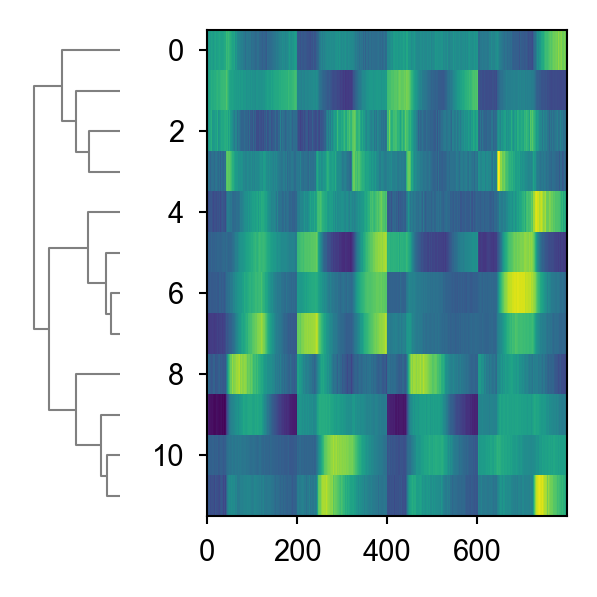

In [11]:
# reorder clusters
R2 = R[R["good"]].copy()
time_cols = R.columns[R.columns.str.startswith("time_")].tolist()
X = R2[time_cols].values
# scaler = MinMaxScaler(feature_range=(0, 1))
scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(1.0, 99.0), unit_variance=True)
X_norm = scaler.fit_transform(X.T).T

cluster_ids = R2["cluster"]
cluster_means = np.array([X_norm[cluster_ids == c].mean(axis=0) for c in np.unique(cluster_ids)])
distance_matrix = dist.pdist(cluster_means, metric="cosine")
Z = sch.linkage(distance_matrix, method="complete")
row_order = sch.leaves_list(Z)
sorted_matrix = cluster_means[row_order, :]

fig = plt.figure(figsize=(2,2), dpi=300)
gs = fig.add_gridspec(1, 2, width_ratios=[1, 4])

# Row Dendrogram
ax_row_dendro = fig.add_subplot(gs[0,0])
with plt.rc_context({'lines.linewidth': 0.5}):
    sch.dendrogram(Z, orientation='left', ax=ax_row_dendro, no_labels=True, color_threshold=0, above_threshold_color='gray')
ax_row_dendro.set_xticks([])
ax_row_dendro.set_yticks([])
ax_row_dendro.invert_yaxis()
for sp in ["top", "right", "bottom", "left"]:
    ax_row_dendro.spines[sp].set_visible(False)

ax_img = fig.add_subplot(gs[0,1])
ax_img.imshow(sorted_matrix, aspect="auto", interpolation="None")

plt.tight_layout()
plt.show()

In [12]:
# re-assign cluster ID based on the similarity
lut = {}
for (i, j) in enumerate(row_order):
    lut[j+1] = i
print(lut)

cluster_ids = np.array([lut[int(e)] for e in cluster_ids])
cluster_ids += 1

k = 0
for i, r in R.iterrows():
    if r["good"]:
        R.at[i, "cluster"] = int(cluster_ids[k])
        k += 1
    else:
        R.at[i, "cluster"] = -1

{np.int32(8): 0, np.int32(5): 1, np.int32(2): 2, np.int32(12): 3, np.int32(10): 4, np.int32(11): 5, np.int32(1): 6, np.int32(7): 7, np.int32(4): 8, np.int32(3): 9, np.int32(6): 10, np.int32(9): 11}


In [13]:
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,time_791,time_792,time_793,time_794,time_795,time_796,time_797,time_798,time_799,cluster
0,0,OGL,1,True,-0.260765,-0.105565,0.046531,-0.198793,-0.015703,-0.029045,...,1.257169,1.204909,1.397099,1.380041,1.275232,1.291227,1.296163,1.250495,1.334867,7.0
1,0,OGL,2,False,-1.420896,-1.380728,-1.332167,-1.412719,-1.457823,-1.442253,...,1.288994,1.281787,1.346783,1.326102,1.235995,1.276723,1.297286,1.161653,1.249644,-1.0
2,0,OGL,3,True,-1.361651,-1.448131,-1.388264,-1.462015,-1.470180,-1.442105,...,0.643437,0.741191,0.234685,0.442145,0.670105,0.816256,0.819974,0.920078,1.215244,10.0
3,0,OGL,4,False,-1.450398,-1.519597,-1.259635,-1.395236,-1.446172,-1.191424,...,1.216849,1.056623,1.059953,1.004428,1.030726,0.947560,0.836148,0.908323,0.940547,-1.0
4,0,OGL,5,False,0.989353,1.254396,1.327575,1.089715,0.822304,0.767290,...,-0.555345,-0.888348,-1.029293,-0.879512,-1.127863,-0.897568,-0.762735,-0.507708,-0.734061,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,8,IGL,176,False,0.384106,0.348831,0.106594,0.014571,0.171919,0.087411,...,0.006624,0.127840,0.511245,0.270663,0.511199,0.384550,0.629391,0.299628,-0.333441,-1.0
1334,8,IGL,177,True,0.369082,0.333936,0.428675,0.394009,0.046025,0.187033,...,0.256488,0.473804,0.597549,0.558918,0.472210,0.241232,0.108963,0.309119,0.516958,11.0
1335,8,IGL,178,True,-0.551695,-0.672312,-0.734733,-1.049439,-0.814104,-0.024008,...,0.761890,0.440239,0.404533,0.788688,1.000730,0.608467,0.500419,0.485964,0.647111,5.0
1336,8,IGL,183,True,-0.091565,-0.053233,-0.024039,-0.082339,0.057786,0.221866,...,0.532442,0.640355,0.697110,0.622841,0.400060,0.007892,0.123228,0.280279,0.145476,11.0


### Plot results

In [14]:
R2 = R[R["good"]].copy()
R2.reset_index(inplace=True)
time_cols = [col for col in R2.columns if col.startswith("time_")]
X = R2[time_cols].values
scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(1.0, 99.0), unit_variance=True)
X_norm = scaler.fit_transform(X.T).T
R2_norm = R2.copy()
R2_norm[time_cols] = X_norm

In [15]:
def plot_clustering2(df, cluster_cmap, stimulus_train, vmin=0, vmax=1, dt=0.05, figsize=(5,5), figsavename=None):
    def _plot_stimulus_train(axis, t, y):
        axis.plot(t, y, color="gray", lw=1)
        axis.set_xlim([t[0], t[-1]])
        axis.set_ylim([-0.25, 1.25])
        axis.axis("off")

    def _configure_axis(ax, label, yticks, ylim, labelpad=0, aspect=10):
        ax.set_aspect(aspect)
        ax.set_ylabel(label, labelpad=labelpad)
        ax.set_yticks(yticks)
        ax.set_ylim(ylim)
        ax.set_xticks([])
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)

    def _configure_axis2(ax, label, ylim, labelpad=0):
        ax.set_ylabel(label, labelpad=labelpad)
        ax.yaxis.label.set(rotation='horizontal', ha='right', va='center')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_ylim(ylim)
        for sp in ["top", "right", "bottom", "left"]:
            ax.spines[sp].set_visible(False)


    df_sorted = df.sort_values(by='cluster')
    data = df_sorted.filter(regex="^time_").to_numpy()
    cluster_ids = df_sorted["cluster"]

    fig = plt.figure(figsize=figsize, dpi=300)
    gs = fig.add_gridspec(4, 6, width_ratios=[0.02, 0.3, 0.3, 0.3, 0.3, 0.04], height_ratios=[1, 0.04, 0.04, 0.04], wspace=0.08, hspace=0.1)

    # Cluster Color Annotations
    ax = fig.add_subplot(gs[0, 5])
    for k, i in enumerate(cluster_ids):
        ax.add_patch(mpatches.Rectangle((0, data.shape[0] - k - 1), 1, 1, color=cluster_cmap[i], lw=0))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, data.shape[0])
    ax.axis('off')

    # Plot Heatmaps
    for i in range(4):
        ax = fig.add_subplot(gs[0, 1 + i])
        ax.imshow(data[:, i * (200):(i + 1) * (200)], cmap="bone_r", vmin=vmin, vmax=vmax, aspect='auto', interpolation="nearest")
        ax.axis("off")
    
    # plot stimulus train
    t = np.arange(stimulus_train.size)
    _plot_stimulus_train(fig.add_subplot(gs[1, 1]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[2, 1]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[1, 2]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[2, 2]), t, 1- stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[1, 3]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[2, 3]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[1, 4]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[2, 4]), t, 1- stimulus_train)

    # Draw the scale bar
    ax = fig.add_subplot(gs[3, 1])
    ax.plot([t[0], t[5000]], [-0.5,-0.5], color='black', lw=2)
    ax.text(t[2500], 0.8, '5 sec', color='black', ha='center', va='center', rotation=0)
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(-1, 1)
    ax.axis("off")

    ax = fig.add_subplot(gs[0, 0])
    _configure_axis(ax, "Neurons", [0, data.shape[0]], [data.shape[0], 0], labelpad=-10)
    ax = fig.add_subplot(gs[1, 0])
    _configure_axis2(ax, "Int.", [-0.25, 1.25], labelpad=2)
    ax = fig.add_subplot(gs[2, 0])
    _configure_axis2(ax, "DoLP", [-0.25, 1.25])

    if figsavename:
        plt.savefig(figsavename)
        print(f"Figure saved as {figsavename}")
    plt.show()

Figure saved as /flash/ReiterU/tmp/tomo_ZNSWDEBKEOLC/clustering.pdf


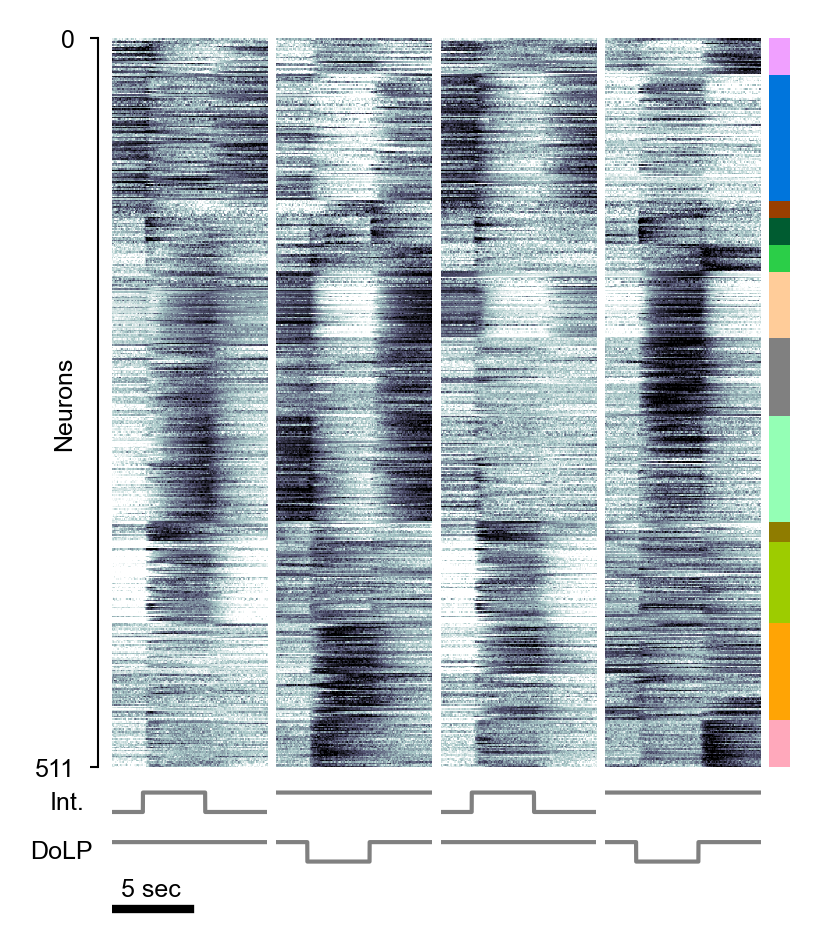

In [16]:
t = np.arange(10000) * 1e-3
y = np.zeros_like(t)
y[0:2000] = 0
y[2000:6000] = 1
y[6000:10000] = 0

alphabet_colors = [
    "#F0A0FF",
    "#0075DC",
    "#993F00", "#005C31",
    "#2BCE48", "#FFCC99", "#808080", "#94FFB5", "#8F7C00", "#9DCC00",
    # "#C20088",
    #"#003380",
    "#FFA405", "#FFA8BB", "#426600", "#FF0010",
    "#5EF1F2", "#00998F", "#E0FF66", "#740AFF", "#990000", "#FFFF80",
    "#FFE100", "#FF5005"
]
alphabet_cmap = mpl.colors.ListedColormap(alphabet_colors, name='alphabet')
color_map = {i: alphabet_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

mpl.rcParams.update({
    'font.size': 6,
    'axes.titlesize': 6,
    'legend.fontsize': 6,
})

plot_clustering2(R2_norm, color_map, y, vmin=-1.5, vmax=3, figsize=(3,3.8), figsavename=os.path.join(tmpdir, "clustering.pdf"))

Figure saved as /flash/ReiterU/tmp/tomo_ZNSWDEBKEOLC/clustering_mean.pdf


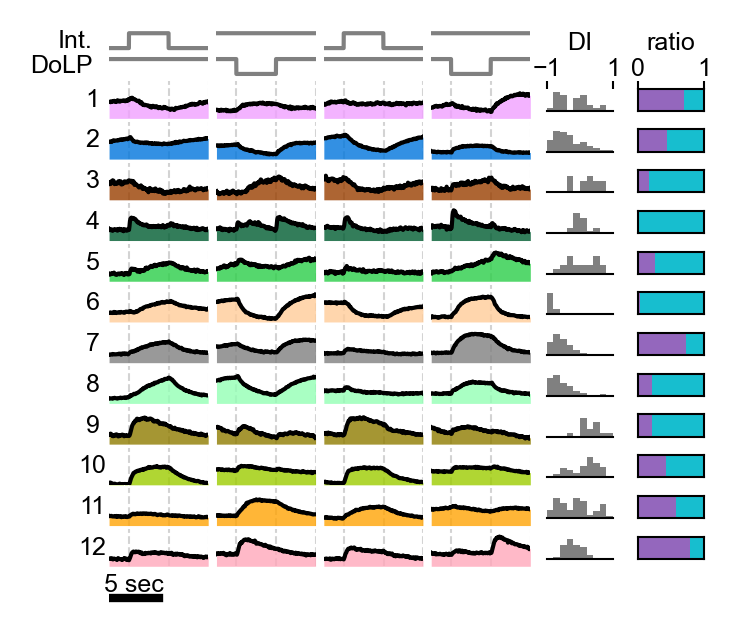

In [76]:
def plot_cluster_average2(df, cluster_cmap, stimulus_train, ymin=0, ymax=1, figsize=(5,5), figsavename=None):
    def _plot_stimulus_train(axis, t, y):
        axis.plot(t, y, color="gray", lw=1)
        axis.set_xlim([t[0], t[-1]])
        axis.set_ylim([-0.25, 1.25])
        axis.axis("off")

    def _configure_axis(ax, label, ylim, labelpad=0):
        ax.set_ylabel(label, labelpad=labelpad)
        ax.yaxis.label.set(rotation='horizontal', ha='right', va='center')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_ylim(ylim)
        for sp in ["top", "right", "bottom", "left"]:
            ax.spines[sp].set_visible(False)

    def _configure_axis2(ax, label, labelpad=0, aspect=10):
        ax.set_aspect(aspect)
        ax.set_ylim(0,1)
        ax.set_xlim(0,1)
        ax.text(0.5, 0.5, label, ha="center", va="center")        
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ["top", "right", "bottom", "left"]:
            ax.spines[sp].set_visible(False)

    time_cols = [col for col in df.columns if col.startswith("time_")]
    means = df.groupby('cluster')[time_cols].mean()
    num_clusters = means.shape[0]
    t = np.arange(int(means.shape[1]/4))

    fig = plt.figure(figsize=figsize, dpi=300)
    gs = fig.add_gridspec(num_clusters+3, 7,
                          width_ratios=[0.05, 0.3, 0.3, 0.3, 0.3, 0.25, 0.25],
                          height_ratios=[0.6, 0.6] + [1,] * num_clusters + [1],
                          wspace=0.1, hspace=0.1)

    # distribution of rho
    # for (k, c) in enumerate(sorted(df["cluster"].unique())):
    #     df_filtered = df[df["cluster"] == c][time_cols].to_numpy()
    #     rho = []
    #     for x in df_filtered:
    #         a, _ = pearsonr(x[200:400], x[600:800])
    #         rho.append(a)
    #     h, bin_edges = np.histogram(rho, range=[-1,1], bins=10, density=False)
    #     ax = fig.add_subplot(gs[k+2, 5])
    #     pos = ax.get_position()
    #     ax.set_position([pos.x0+0.01, pos.y0 + 0.01, pos.width-0.02, pos.height - 0.02])
    #     ax.imshow(h[np.newaxis, :], vmin=0, vmax=h.max(), aspect="auto", cmap="Purples", extent=[-1, 1, 0, 1])
    #     if k == 0:
    #         ax.set_xlabel(r"$\rho$", labelpad=2)
    #         ax.set_xticks([-1, 1])
    #         ax.tick_params(axis='x', pad=0)
    #         ax.xaxis.set_label_position('top')  # Moves the x-axis label to the top
    #         ax.xaxis.set_ticks_position('top')  # Moves the x-axis label to the top
    #     else:
    #         ax.set_xticks([])
    #         ax.set_xticklabels([])
    #     ax.set_yticks([])

    for (k, c) in enumerate(sorted(df["cluster"].unique())):
        df_filtered = df[df["cluster"] == c][time_cols].to_numpy()
        rho = []
        for x in df_filtered:
            a, _ = pearsonr(x[200:400], x[600:800])
            rho.append(a)
        h, bin_edges = np.histogram(rho, range=[-1,1], bins=10, density=False)
        bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
        ax = fig.add_subplot(gs[k+2, 5])
        pos = ax.get_position()
        ax.set_position([pos.x0+0.01, pos.y0 + 0.01, pos.width-0.02, pos.height - 0.02])
        ax.bar(bin_centers, h, width=bin_edges[1]-bin_edges[0], align="center", lw=0, alpha=1, color="gray")
        ax.set_xlim(-1,1)
        ax.set_ylim(0, h.max()+1)
        if k == 0:
            ax.set_xlabel(r"DI", labelpad=2)
            ax.set_xticks([-1, 1])
            ax.tick_params(axis='x', pad=0)
            ax.xaxis.set_label_position('top')  # Moves the x-axis label to the top
            ax.xaxis.set_ticks_position('top')  # Moves the x-axis label to the top
        else:
            ax.set_xticks([])
            ax.set_xticklabels([])
        ax.set_yticks([])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)

    # show OGL/IGL ratio
    for (k, c) in enumerate(sorted(df["cluster"].unique())):
        df2 = df[df["cluster"] == c]
        c1 = df2[df2["region"] == "OGL"].shape[0]
        c2 = df2[df2["region"] == "IGL"].shape[0]
        r1 = c1 / (c1 + c2)
        r2 = c2 / (c1 + c2)
        ax = fig.add_subplot(gs[k+2, 6])
        pos = ax.get_position()
        ax.set_position([pos.x0+0.01, pos.y0 + 0.01, pos.width-0.02, pos.height - 0.02])
        ax.barh(0, r1, height=1, color="#9467bd")
        ax.barh(0, r2, left=r1, height=1, color="#17becf")
        ax.set_ylim(-0.5,0.5)
        ax.set_xlim(0, 1)
        if k == 0:
            ax.set_xlabel("ratio", labelpad=2)
            ax.set_xticks([0, 1])
            ax.tick_params(axis='x', pad=0)
            ax.xaxis.set_label_position('top')  # Moves the x-axis label to the top
            ax.xaxis.set_ticks_position('top')  # Moves the x-axis label to the top
        else:
            ax.set_xticks([])
        ax.set_yticks([])

    # show cluster mean
    for (k, c) in enumerate(sorted(df["cluster"].unique())):
        for i in range(4):
            ax = fig.add_subplot(gs[k+2, i+1])
            y = means.loc[c][i * (200):(i + 1) * (200)]
            ax.plot(t, y, color="k", zorder=11, linewidth=1)
            ax.fill_between(t, ymin, y, color=cluster_cmap[c], zorder=10, alpha=0.8, linewidth=0, antialiased=True)
            ax.vlines([40, 120, 200, 240, 400], ymin, ymax, colors="lightgray", linestyles="dashed", lw=0.5)
            ax.set_xlim([t[0], t[-1]])
            ax.set_ylim([ymin, ymax])
            ax.axis("off")

    t = np.arange(stimulus_train.size)
    _plot_stimulus_train(fig.add_subplot(gs[0, 1]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[1, 1]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[0, 2]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[1, 2]), t, 1- stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[0, 3]), t, stimulus_train)
    _plot_stimulus_train(fig.add_subplot(gs[1, 3]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[0, 4]), t, np.ones_like(t))
    _plot_stimulus_train(fig.add_subplot(gs[1, 4]), t, 1- stimulus_train)
    
    for i in range(num_clusters):
        ax = fig.add_subplot(gs[i+2, 0])
        _configure_axis2(ax, f"{i+1}", [0, 1])

    ax = fig.add_subplot(gs[0, 0])
    _configure_axis(ax, "Int.", [-0.25, 1.25], labelpad=-2)
    ax = fig.add_subplot(gs[1, 0])
    _configure_axis(ax, "DoLP", [-0.25, 1.25], labelpad=-2)

    ax = fig.add_subplot(gs[num_clusters+2, 1])
    ax.plot([t[0], t[5000]], [-0.5,-0.5], color='black', lw=2)
    ax.text(t[2500], 0.2, '5 sec', color='black', ha='center', va='center', rotation=0)
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(-1, 1)
    ax.axis("off")

    if figsavename:
        plt.savefig(figsavename)
        print(f"Figure saved as {figsavename}")
    plt.show()

mpl.rcParams.update({
    'font.size': 6,
    'axes.titlesize': 6,
    'legend.fontsize': 6,
})

plot_cluster_average2(R2_norm, color_map, y, ymin=-2.2, ymax=4, figsize=(2.7,2.5), figsavename=os.path.join(tmpdir, "clustering_mean.pdf"))

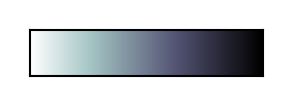

In [18]:
gradient = np.linspace(0, 1, 256).reshape(1, -1)
gradient = np.vstack([gradient] * 20)

fig, ax = plt.subplots(figsize=(1, 0.2), dpi=300)
ax.imshow(gradient, aspect='auto', cmap='bone_r')
# ax.set_axis_off()
ax.set_xticks([])
ax.set_yticks([])
plt.savefig(os.path.join(tmpdir, "bone_r_colormap.pdf"))
plt.show()

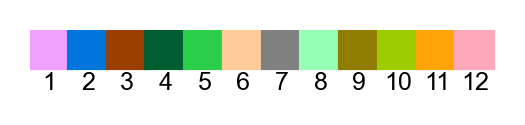

In [19]:
fig, ax = plt.subplots(figsize=(2, 0.2), dpi=300)
for i in range(1, len(color_map)+1):  # cmap.N is the number of colors in tab10 (10)
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=color_map[i]))
    ax.text(i + 0.5, -0.1, str(i), ha="center", va="top")
ax.set_xlim(1, len(color_map)+1)
ax.set_ylim(-0.2, 1)
ax.axis("off")
plt.savefig(os.path.join(tmpdir, "cluster_colormap.pdf"))
plt.show()

### UMAP visualization

In [20]:
X = R[R["good"]].filter(regex="^time_").to_numpy()
scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(1.0, 99.0), unit_variance=True)
X_norm = scaler.fit_transform(X.T).T
# scaler2 = StandardScaler()
# X_norm = scaler2.fit_transform(X_norm1)

# sparse PCA
S = []
for i in range(4):
    D = X_norm[:, i * (200):(i + 1) * (200)]
    spca = SparsePCA(n_components=8, random_state=2025, alpha=1.0, tol=1e-5)
    D_spca = spca.fit_transform(D)
    S.append(D_spca)
S = np.hstack(S)

In [21]:
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
})

2025-06-19 11:17:47.975230: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750299468.582618 3695980 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750299468.700948 3695980 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1750299469.668483 3695980 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1750299469.668524 3695980 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1750299469.668526 3695980 computation_placer.cc:177] computation placer alr

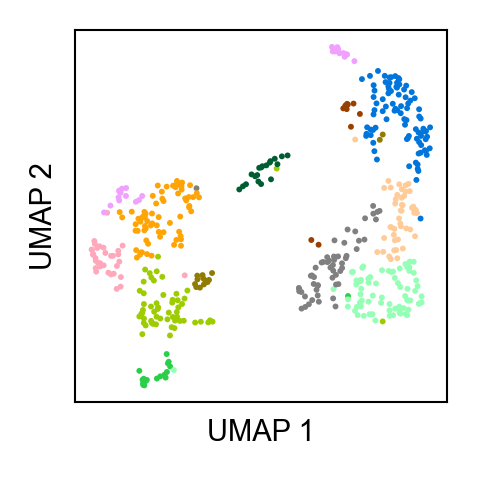

In [22]:
adata = AnnData(S)
adata.obsm['X_pca'] = S

sc.pp.neighbors(adata, n_neighbors=8, metric='cosine', use_rep='X_pca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.2, spread=2.0)

fig, ax = plt.subplots(figsize=(1.6,1.6), dpi=300)
um = adata.obsm['X_umap']
point_colors = [color_map[e] for e in R2["cluster"]]
scatter = ax.scatter(um[:, 0], um[:, 1], c=point_colors, s=2, alpha=1, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
# ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "umap.pdf"), bbox_inches='tight')
plt.show()

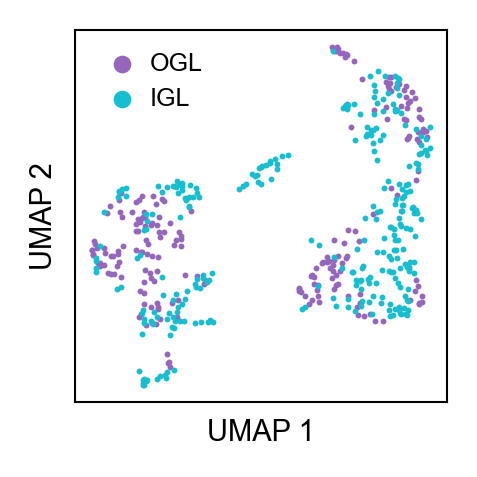

In [23]:
fig, ax = plt.subplots(figsize=(1.6,1.6), dpi=300)

um = adata.obsm['X_umap']
ogl_idx = R2[R2["region"] == "OGL"].index
igl_idx = R2[R2["region"] == "IGL"].index

ax.scatter(um[ogl_idx, 0], um[ogl_idx, 1], color='#9467bd', s=2, alpha=1, lw=0, label="OGL")
ax.scatter(um[igl_idx, 0], um[igl_idx, 1], color='#17becf', s=2, alpha=1, lw=0, label="IGL")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(frameon=False, loc="upper left", markerscale=3, fontsize=6, handletextpad=0.1)
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "umap_region.pdf"), bbox_inches='tight')
plt.show()

Number of OGL neurons: 214
Number of IGL neurons: 297


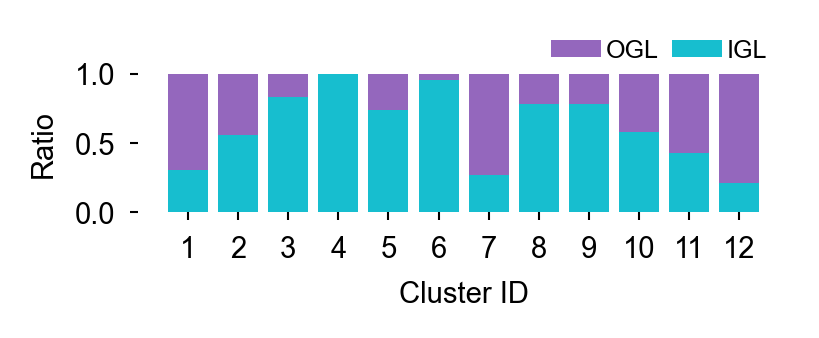

In [24]:
df1 = R2[R2["region"] == "OGL"]
df2 = R2[R2["region"] == "IGL"]
print("Number of OGL neurons:", df1.shape[0])
print("Number of IGL neurons:", df2.shape[0])

c1, c2 = [], []
for i in range(1, int(R2["cluster"].max())+1):
    c1.append(df1[df1["cluster"] == i].shape[0])
    c2.append(df2[df2["cluster"] == i].shape[0])
c1 = np.array(c1)
c2 = np.array(c2)

r1 = c1 / (c1 + c2)
r2 = c2 / (c1 + c2)
x = np.arange(1, r1.size + 1)

fig, ax = plt.subplots(figsize=(2.8,0.6), dpi=300)
ax.bar(x, r1, bottom=r2, width=0.8, color="#9467bd", label="OGL")
ax.bar(x, r2, width=0.8, color="#17becf", label="IGL")
ax.set_xlim(0,R["cluster"].max()+1)
ax.set_ylim(0,1)
ax.set_xlabel("Cluster ID")
ax.set_ylabel("Ratio")
ax.set_xticks(np.arange(1, R["cluster"].max()+1))
# ax.xaxis.set_tick_params(labelsize=6)
ax.legend(frameon=False, bbox_to_anchor=(0.6, 0.92), ncol=2, columnspacing=0.5, markerscale=1,  handletextpad=0.2, fontsize=6)
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)

plt.savefig(os.path.join(tmpdir, "cluster_ratios.pdf"), bbox_inches='tight')
plt.show()

### Plot cells in a given cluster

In [25]:
def plot_chirp_eta(df, neuron_id, stimulus_train, vmin1=-1, vmax1=3, vmin2=-1, vmax2=3, cmap_name="bwr",
                   ylabels=True, figsize=(6,2.5), figsavename=None, show_plot=True):

    def _configure_axis(axis, show_ytick=False, ylabel="", labelpad=0):
        if show_ytick:
            axis.set_yticks([0, 1])
        else:
            axis.set_yticks([])
        axis.set_ylabel(ylabel, labelpad=labelpad)
        axis.yaxis.label.set(rotation='horizontal', ha='right', va='center')
        axis.set_xticks([])
        axis.set_xlim([t[0], t[-1]])
        axis.set_ylim([-0.25, 1.25])
        for sp in ["top", "right", "bottom", "left"]:
            axis.spines[sp].set_visible(False)

    t = df.index.get_level_values("time").unique()
    t = t[0:200]
    t /= 1000 # convert msec to sec

    fig = plt.figure(figsize=figsize, dpi=300)
    gs = fig.add_gridspec(7, 2,
                          height_ratios=[0.25,0.25,0.8,1,0.2,0.8,1,],
                          wspace=0.1, hspace=0.15)

    for k, i in enumerate([1, 2, 4, 5]):
        df_filtered = df.xs((i, neuron_id), level=["session", "neuron"])
        mat = df_filtered.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
        mat = mat[:, 0:200]
        # smooth along rows
        mat = ndi.uniform_filter1d(mat, size=3, axis=1, mode='nearest')
        ax = fig.add_subplot(gs[2*(k//2)+(k//2)+2, k%2])
        ax.imshow(mat, vmin=vmin1, vmax=vmax1, cmap=cmap_name, aspect="auto", interpolation="nearest", extent=[t[0], t[-1], mat.shape[0], 1])
        if k == 0 or k == 2:
            if ylabels:
                ax.set_ylabel("Trials")
        else:
            ax.set_yticks([])
        ax.set_xticks([])

        mean = np.nanmean(mat, axis=0)
        error = np.nanstd(mat, axis=0)
        mean = ndi.uniform_filter1d(mean, size=3)
        error = ndi.uniform_filter1d(error, size=3)
        ax = fig.add_subplot(gs[2*(k//2)+(k//2)+3, k%2])
        ax.plot(t, mean, color="k", lw=1, zorder=100)
        ax.fill_between(t, mean-error, mean+error, color="lightgray", alpha=1, linewidth=0, antialiased=True, zorder=90)
        # ax.vlines([0, 4], vmin2, vmax2, colors="gray", linestyles="dashed", lw=0.5)
        if k == 0 or k == 2:
            if ylabels:
                ax.set_ylabel("Activity")
        else:
            ax.set_yticks([])
        ax.set_ylim([vmin2, vmax2])
        ax.set_xlim([t[0], t[-1]])
        ax.set_xticks([])
        for sp in ["top", "right", "bottom", "left"]:
            ax.spines[sp].set_visible(False)

    # plot luminance and polarization trace
    t2 = np.linspace(t[0], t[-1], stimulus_train.size)
    ax = fig.add_subplot(gs[0,0])
    ax.plot(t2, stimulus_train, color="gray", lw=1)
    _configure_axis(ax, ylabel="Int.", show_ytick=False, labelpad=5)
    ax = fig.add_subplot(gs[1,0])
    ax.plot(t2, np.ones_like(t2), color="gray", lw=1)
    _configure_axis(ax, ylabel="DoLP", show_ytick=False, labelpad=5)
    ax = fig.add_subplot(gs[0,1])
    ax.plot(t2, np.ones_like(t2), color="gray", lw=1)
    _configure_axis(ax)
    ax = fig.add_subplot(gs[1,1])
    ax.plot(t2, 1 - stimulus_train, color="gray", lw=1)
    _configure_axis(ax)

    # plt.tight_layout()
    if figsavename:
        plt.savefig(figsavename, bbox_inches='tight')
        print(f"Figure saved as {figsavename}")
    if show_plot:
        plt.show()
    plt.close()

In [26]:
# target_id = 9
# matching_rows = R[R["cluster"] == target_id]

# t = np.arange(10000) * 1e-3
# y = np.zeros_like(t)
# y[0:2000] = 0
# y[2000:6000] = 1
# y[6000:10000] = 0

# mpl.rcParams.update({
#     'font.size': 6,
#     'axes.titlesize': 6,
#     'legend.fontsize': 6,
# })

# for i, r in matching_rows.iterrows():
#     rec, nid = r["recording"], r["neuron"]
#     print(rec, nid)
#     plot_chirp_eta(E.loc[rec], nid, y, vmin1=-2, vmax1=3, vmin2=-1.5, vmax2=3, cmap_name="bone_r",
#                    ylabels=True, figsize=(1.2,2.0), show_plot=True)

### Cluster 6

Figure saved as /flash/ReiterU/tmp/tomo_ZNSWDEBKEOLC/chirp/rec05_cell105.pdf


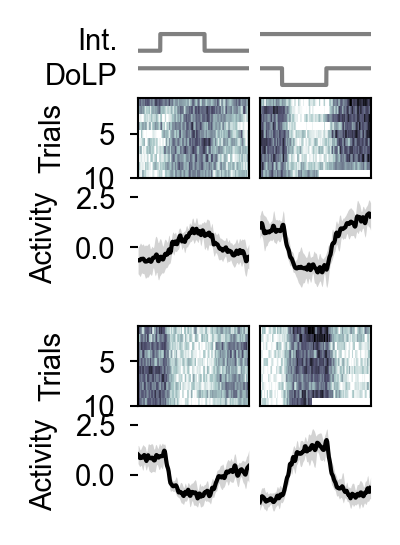

In [27]:
rec = 5
nid = 105
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=3., vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=True, figsize=(1.0,2.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Cluster 9

Figure saved as /flash/ReiterU/tmp/tomo_ZNSWDEBKEOLC/chirp/rec05_cell017.pdf


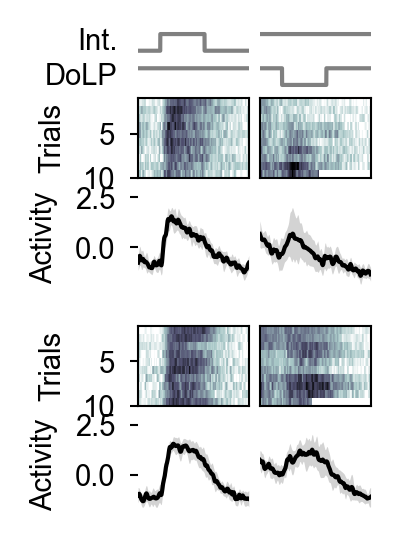

In [28]:
rec = 5
nid = 17
plot_chirp_eta(E.loc[rec], nid, y, vmin1=-1.5, vmax1=3., vmin2=-2, vmax2=3, cmap_name="bone_r",
               ylabels=True, figsize=(1.0,2.1), show_plot=True, figsavename=os.path.join(tmpdir, f"chirp/rec{rec:02d}_cell{nid:03d}.pdf"))

### Degree index

In [29]:
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
})

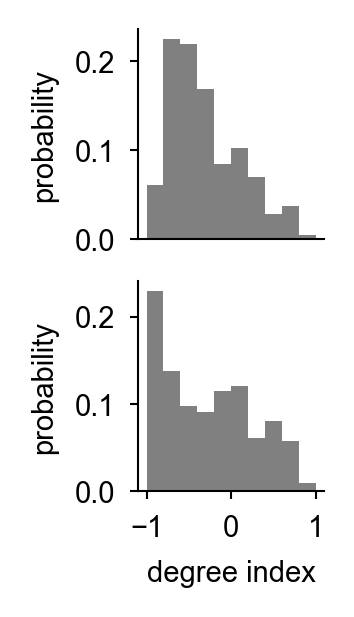

In [30]:
rho_ogl = []
X = R[R["good"] & (R["region"] == "OGL")].filter(regex="^time_").to_numpy()
for x in X:
    b, _ = pearsonr(x[200:400], x[600:800])
    rho_ogl.append(b)
rho_ogl = np.array(rho_ogl)

rho_igl = []
X = R[R["good"] & (R["region"] == "IGL")].filter(regex="^time_").to_numpy()
for x in X:
    b, _ = pearsonr(x[200:400], x[600:800])
    rho_igl.append(b)
rho_igl = np.array(rho_igl)

fig = plt.figure(figsize=(0.8,2.0), dpi=300)
gs = fig.add_gridspec(2, 1)

h_ogl, bin_edges = np.histogram(rho_ogl, range=[-1,1], bins=10, density=False)
h_igl, bin_edges = np.histogram(rho_igl, range=[-1,1], bins=10, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

for i in range(2):
    ax = fig.add_subplot(gs[i, 0])
    if i == 0:
        h = h_ogl / h_ogl.sum()
        bar_color = "#51C2B8"
    elif i == 1:
        h = h_igl / h_igl.sum()
        bar_color = "#3A9DD7"
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, h, width=bin_edges[1]-bin_edges[0], align="center", lw=0, alpha=1, color="gray")
    ax.set_xlim(-1.1,1.1)
    ax.set_ylabel("probability")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if i == 0:
        ax.set_xticks([])
    if i == 1:
        ax.set_xlabel("degree index")
plt.savefig(os.path.join(tmpdir, "degree_index.pdf"), bbox_inches='tight')
plt.show()

In [31]:
print(rho_ogl.size, rho_igl.size)

214 297


In [32]:
rho_igl

array([ 0.41329346,  0.15805228,  0.29012335,  0.67007501, -0.31926045,
        0.50448136, -0.08502833, -0.49564086,  0.25967239, -0.34336603,
        0.3519872 , -0.41893392,  0.5903655 , -0.03939804,  0.50666555,
        0.08043769, -0.20687483, -0.10026138,  0.10598926,  0.54885139,
        0.19993036,  0.07312818,  0.15289678,  0.3991133 , -0.18472735,
       -0.83924636, -0.860218  , -0.78954433, -0.88693271,  0.59839424,
       -0.91241337, -0.9532127 ,  0.02640715,  0.75399291, -0.58752889,
        0.71909581, -0.96529727,  0.70246704,  0.67431362, -0.51386836,
       -0.23358657, -0.71861904, -0.8056891 , -0.78284717, -0.42679273,
        0.25020257,  0.01291117,  0.28602346, -0.95516583, -0.54780273,
       -0.95501015, -0.16068611, -0.94601185, -0.89116778, -0.78756318,
       -0.70436564, -0.83533233, -0.5185852 , -0.94438043, -0.74800168,
        0.39734796, -0.88908583,  0.7367639 , -0.96344848, -0.62379266,
       -0.08011653, -0.95993361, -0.93945412,  0.7111298 , -0.57

In [33]:
rho_ogl

array([-4.79463882e-01,  3.86508177e-01,  3.22952351e-01, -8.94110848e-01,
       -8.69076307e-01, -8.35422015e-01,  5.20058237e-02, -5.37442341e-01,
        8.41104621e-02, -6.80704483e-01, -3.73879598e-01,  1.25757791e-01,
        6.75771746e-01,  8.05441991e-01,  2.29686904e-02,  1.20304250e-01,
       -5.00645550e-01,  7.53753462e-01,  7.15718899e-01,  5.60528619e-01,
       -1.12700500e-01,  3.80793628e-01, -9.37927882e-02, -6.63357560e-01,
       -6.27146254e-01, -1.35679673e-01,  6.99938567e-01,  5.04955647e-02,
        5.19004727e-01,  2.75316916e-01, -3.94948267e-01,  1.53629536e-01,
       -2.22863074e-01, -1.71195635e-01, -6.08739140e-01,  3.27423013e-01,
       -5.03851209e-01, -1.24829147e-01, -4.84198929e-01,  3.49098667e-01,
       -6.90599213e-01, -5.65046733e-01,  1.25737778e-01, -2.54302510e-01,
       -4.46044292e-01, -4.50717948e-01, -2.70542756e-01, -6.30304236e-01,
       -1.08659427e-01,  3.95542633e-01, -7.36720493e-01, -2.50128521e-01,
       -3.94222244e-01, -

In [81]:
from scipy.stats import fisher_exact, chi2_contingency

THRESHOLD = 0.3

# Example data — replace with your actual counts
ogl_positive = np.sum(rho_ogl > THRESHOLD)
ogl_negative = np.sum(rho_ogl <= THRESHOLD)
igl_positive = np.sum(rho_igl > THRESHOLD)
igl_negative = np.sum(rho_igl <= THRESHOLD)

contingency = [[igl_positive, igl_negative],
               [ogl_positive, ogl_negative]]
print(contingency)

chi2, p, _, _ = chi2_contingency(contingency)
print(p)
oddsratio, p = fisher_exact(contingency, alternative='greater')
print(p, oddsratio)

[[np.int64(54), np.int64(243)], [np.int64(24), np.int64(190)]]
0.041772644157433286
0.019868160431185892 1.7592592592592593


In [37]:
from scipy.stats import ttest_ind

t_stat, p_val = ttest_ind(rho_ogl, rho_igl, equal_var=False)  # Welch's t-test

print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:}")

T-statistic: -0.695
P-value: 0.4875215440108841


### Copy data to bucket

In [39]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250601_OGL_IGL_monitor_flip/"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250601_OGL_IGL_monitor_flip/
cp -r /flash/ReiterU/tmp/tomo_STJIJUNWACLX/* /bucket/ReiterU/OLdev/analysis/20250601_OGL_IGL_monitor_flip/
